# Defense results (P3): poisoning and robustness in streaming classifiers

PaySim (10% sample, 625,883 stream rows with 653 frauds; clean held-out test set = steps 600 and later), replayed in
24-step windows. Each attacked stream goes through `defend()` and the learner (online logistic regression) trains
only on the accepted records. Attacks: 6 methods x budgets 0.05 and 0.2 x 3 timings x **3 seeds**.
Numbers are the mean over the 3 seeds; the spread (sd) is shown where it matters.

**What the seeds vary.** The attack draw (which records, which timing positions) and the learner seed. The clean
PaySim sample is the same for all three, so these seeds do not capture sampling variation of the data itself.
The defense thresholds were tuned on seed-0 files of the same sample, so the results are optimistic (see Limitations).

How the tables were produced (`is_poisoned` is stripped before every `defend` call):

```
python -m src.attacks.sweep --clean-dir data/attacked_sample     # results/metrics.csv: defense off vs on, per window
bash scripts/run_multiseed.sh                                    # detection, clean-record loss, subgroups
bash scripts/run_ablation.sh                                     # detector ablation, budget 0.2
python scripts/collect_results.py                                # -> results/summary/*.csv (committed)
```

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

S = Path("../results/summary") if Path("../results/summary").exists() else Path("results/summary")
util = pd.read_csv(S / "utility.csv")
det = pd.read_csv(S / "detection.csv")
abl = pd.read_csv(S / "ablation.csv")

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})
print(len(util), "utility rows,", len(det), "detection rows,", len(abl), "ablation rows;", util.seed.nunique(), "seeds")

222 utility rows, 108 detection rows, 324 ablation rows; 3 seeds


## 1. What does the defense cost when there is no attack?

PR-AUC on the clean test set after the whole stream, no attacker. The defense quarantines a few real frauds (the
fraud class is tiny, so its reference is noisy), which costs about 0.01 PR-AUC.

In [2]:
b = util[util.attack == "none"].groupby("defense")[["pr_auc", "recall"]].agg(["mean", "std"]).round(4)
b

pr_auc          recall        
           mean     std    mean     std
defense                                
off      0.9981  0.0019  0.9827  0.0058
on       0.9868  0.0000  0.9750  0.0067

## 2. Does the defense protect the learner?

Left bar: learner trained on the poisoned stream with no defense. Right bar: trained on what the defense accepted.
Dots are the three seeds.

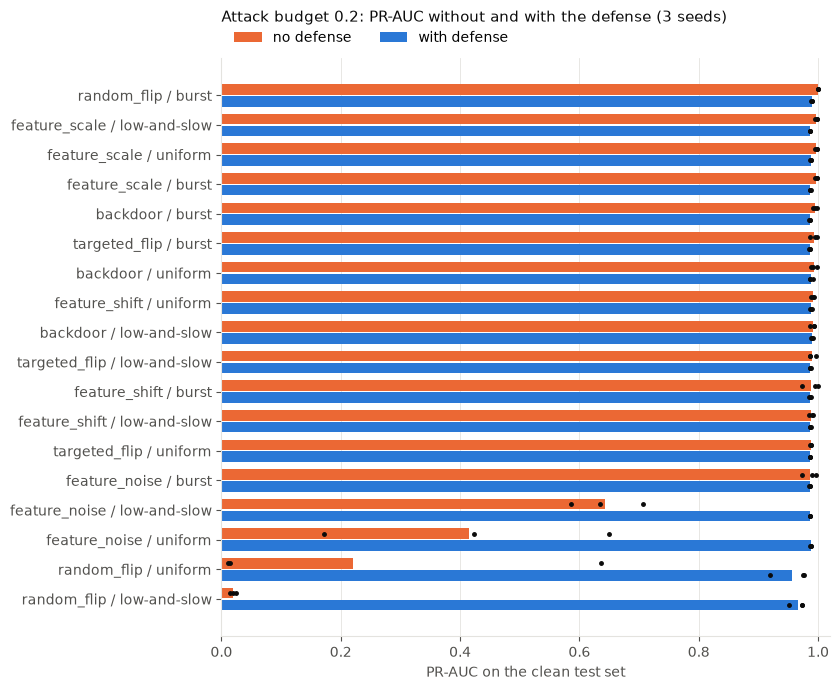

In [3]:
atk = util[util.attack != "none"].copy()
atk["case"] = atk["attack"] + " / " + atk["timing"].str.replace("_", "-")
def chart(budget):
    d = atk[atk.budget == budget]
    order = d[d.defense == "off"].groupby("case").pr_auc.mean().sort_values(ascending=False).index.tolist()
    fig, ax = plt.subplots(figsize=(8.5, 7))
    for j, (dfn, col, off) in enumerate((("off", ORANGE, -0.2), ("on", BLUE, 0.2))):
        g = d[d.defense == dfn]
        for i, c in enumerate(order):
            v = g[g.case == c].pr_auc.to_numpy()
            ax.barh(i + off, v.mean(), height=0.36, color=col, label=("no defense" if dfn == "off" else "with defense") if i == 0 else None)
            ax.plot(v, np.full(len(v), i + off), "o", color=INK, ms=2.5)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
    ax.set_xlim(0, 1.02); ax.set_xlabel("PR-AUC on the clean test set")
    ax.set_title(f"Attack budget {budget}: PR-AUC without and with the defense (3 seeds)", loc="left", color=INK, fontsize=11, pad=26)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()
chart(0.2)

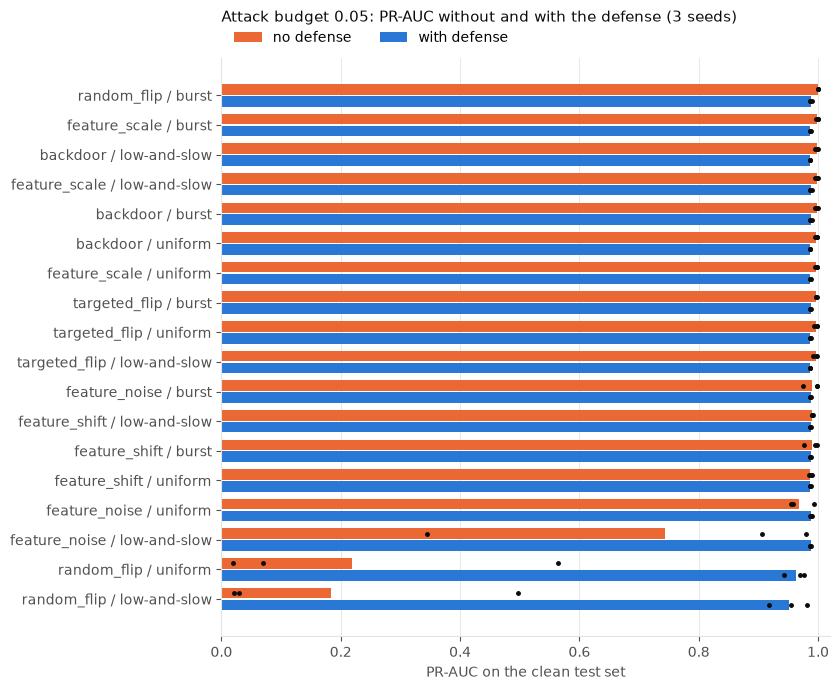

In [4]:
chart(0.05)

In [5]:
t = atk.pivot_table(index=["attack", "budget", "timing"], columns="defense", values="pr_auc", aggfunc=["mean", "std"]).round(3)
t.columns = [f"{a}_{b}" for a, b in t.columns]
t.rename(columns={"mean_off": "no defense", "mean_on": "defended", "std_off": "sd (no def.)", "std_on": "sd (def.)"})

no defense  defended  sd (no def.)  \
attack        budget timing                                             
backdoor      0.05   burst              0.997     0.988         0.003   
                     low_and_slow       0.998     0.987         0.002   
                     uniform            0.997     0.987         0.002   
              0.20   burst              0.995     0.986         0.004   
                     low_and_slow       0.991     0.990         0.004   
                     uniform            0.993     0.988         0.005   
feature_noise 0.05   burst              0.991     0.987         0.013   
                     low_and_slow       0.743     0.988         0.347   
                     uniform            0.969     0.988         0.022   
              0.20   burst              0.986     0.986         0.012   
                     low_and_slow       0.642     0.987         0.061   
                     uniform            0.415     0.988         0.239   
feature_scale 0.05   burst              0.998     0.987         0.002   
                     low_and_slow       0.998     0.988         0.003   
                     uniform            0.997     0.987         0.002   
              0.20   burst              0.997     0.987         0.002   
                     low_and_slow       0.997     0.987         0.001   
                     uniform            0.997     0.987         0.002   
feature_shift 0.05   burst              0.990     0.987         0.012   
                     low_and_slow       0.990     0.987         0.001   
                     uniform            0.987     0.987         0.002   
              0.20   burst              0.989     0.986         0.014   
                     low_and_slow       0.989     0.987         0.003   
                     uniform            0.991     0.988         0.002   
random_flip   0.05   burst              1.000     0.988         0.000   
                     low_and_slow       0.183     0.951         0.272   
                     uniform            0.218     0.962         0.301   
              0.20   burst              1.000     0.989         0.000   
                     low_and_slow       0.019     0.966         0.005   
                     uniform            0.221     0.957         0.360   
targeted_flip 0.05   burst              0.997     0.987         0.001   
                     low_and_slow       0.996     0.987         0.003   
                     uniform            0.997     0.987         0.003   
              0.20   burst              0.994     0.986         0.006   
                     low_and_slow       0.990     0.987         0.005   
                     uniform            0.988     0.987         0.001   

                                   sd (def.)  
attack        budget timing                   
backdoor      0.05   burst             0.001  
                     low_and_slow      0.000  
                     uniform           0.000  
              0.20   burst             0.001  
                     low_and_slow      0.002  
                     uniform           0.002  
feature_noise 0.05   burst             0.001  
                     low_and_slow      0.001  
                     uniform           0.002  
              0.20   burst             0.001  
                     low_and_slow      0.000  
                     uniform           0.001  
feature_scale 0.05   burst             0.000  
                     low_and_slow      0.001  
                     uniform           0.000  
              0.20   burst             0.001  
                     low_and_slow      0.000  
                     uniform           0.001  
feature_shift 0.05   burst             0.001  
                     low_and_slow      0.001  
                     uniform           0.000  
              0.20   burst             0.001  
                     low_and_slow      0.001  
                     uniform           0.002  
random_flip   0.05   burst            

**Reading it.** Without a defense, three kinds of attack break the learner: label floods spread over time
(`random_flip` uniform or low-and-slow, PR-AUC 0.02 to 0.22), and `feature_noise` (0.42 to 0.74 when it is spread out).
With the defense every case is back at 0.95 or higher. The price shows in the attacks that never hurt the learner:
the defended learner sits at about 0.987, not 0.997. Two things the table also shows: a `burst` flood is harmless
here (the learner forgets it before the test, PR-AUC 1.0), and three attacks (`feature_scale`, `backdoor`,
`targeted_flip`) barely move the undefended learner at these budgets, so there is nothing for a defense to gain.

## 3. Which detector does what? (ablation, budget 0.2, 3 seeds)

Mean detection recall over the poisoned records (all three timings).

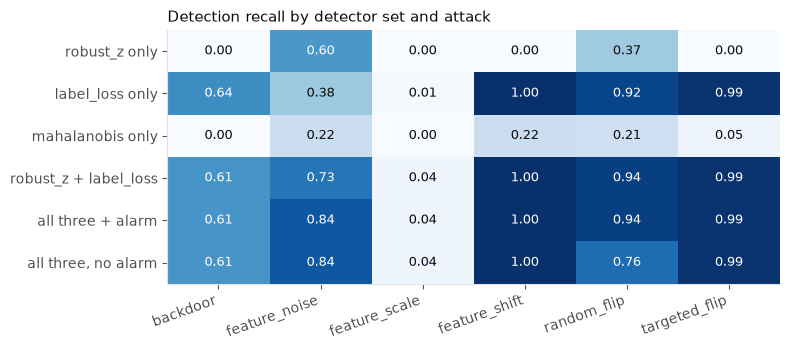

,clean_records_lost,real_frauds_lost
variant,,
robust_z only,0.0001,0.0229
label_loss only,0.0000,0.0140
mahalanobis only,0.0002,0.0003
robust_z + label_loss,0.0001,0.0407
all three + alarm,0.0004,0.0417
"all three, no alarm",0.0006,0.1733


In [6]:
order = ["robust_z only", "label_loss only", "mahalanobis only", "robust_z + label_loss", "all three + alarm", "all three, no alarm"]
rec = abl.groupby(["variant", "attack"]).recall.mean().unstack().loc[order]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.imshow(rec.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(rec.shape[1])); ax.set_xticklabels(rec.columns, rotation=20, ha="right")
ax.set_yticks(range(rec.shape[0])); ax.set_yticklabels(rec.index); ax.grid(False)
for i in range(rec.shape[0]):
    for j in range(rec.shape[1]):
        v = rec.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.55 else INK, fontsize=9)
ax.set_title("Detection recall by detector set and attack", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()
cost = abl.groupby("variant").agg(clean_records_lost=("clean_loss", "mean"), real_frauds_lost=("clean_fraud_loss", "mean")).loc[order].round(4)
cost

**Reading it.** No single detector wins. `label_loss` does most of the work on label attacks and on
`feature_shift`; `robust_z` is the only one with a useful `feature_noise` score on its own; Mahalanobis alone is weak
but adds to the ensemble on `feature_noise` (0.73 to 0.84). The fraud-label alarm matters for `random_flip`: without it
17% of the real frauds are quarantined and recall falls from 0.94 to 0.76. `feature_scale` is not detected by any
variant.

## 4. Does the defense treat clean records fairly?

Share of **clean** records quarantined, by transaction type and by amount quartile (mean over all 108 attacked files).

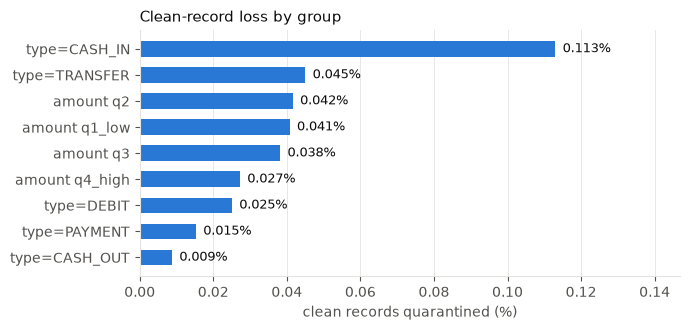

overall clean-record loss: mean 0.037%, worst file 0.062%


In [7]:
cols = [c for c in det.columns if c.startswith("loss_type=") or c.startswith("loss_amount_bucket=")]
g = det[cols].mean().rename(lambda c: c.replace("loss_", "").replace("amount_bucket=", "amount ")).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(g.index, g.values * 100, color=BLUE, height=0.6)
for i, v in enumerate(g.values * 100):
    ax.text(v + 0.002, i, f"{v:.3f}%", va="center", color=INK, fontsize=9)
ax.set_xlabel("clean records quarantined (%)"); ax.set_xlim(0, max(g.values * 100) * 1.3)
ax.set_title("Clean-record loss by group", loc="left", color=INK, fontsize=11); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("overall clean-record loss: mean %.3f%%, worst file %.3f%%" % (det.clean_loss.mean() * 100, det.clean_loss.max() * 100))

**Reading it.** Every group loses well under 0.2% of its clean records. CASH_IN is the highest, by a factor of
two or more over the others (0.11% against 0.01 to 0.05%). We did not investigate why, so a deployment would need to
check that those customers are not systematically delayed. The fraud class is the group that really pays: on average
4.5% of true frauds are quarantined (1.5 to 8% per file, next section), because their reference has only 20 to 300 rows.

## 5. Detection quality per attack

`recall` and `precision` are measured against the poisoned records; `clean_loss` is the share of clean records
quarantined; `real_frauds_lost` is the share of true (unpoisoned) frauds quarantined, which is what hurts the learner
most; `time_to_detect` is in windows from the first poisoned window.

Precision is low for the attacks that only touch fraud rows (32 to 126 poisoned records): the defense also
quarantines about 0.04% of clean records (roughly 250 rows) and about 30 real frauds, so most of what it flags is not poison.

In [8]:
t = det.groupby("attack").agg(recall=("recall", "mean"), precision=("precision", "mean"), clean_loss_max=("clean_loss", "max"),
                             real_frauds_lost=("clean_fraud_loss", "mean"), time_to_detect=("time_to_detect", "mean"),
                             poisoned_rows=("n_poisoned", "mean")).round(4)
t

,recall,precision,clean_loss_max,real_frauds_lost,time_to_detect,poisoned_rows
attack,,,,,,
backdoor,0.6275,0.1677,0.0004,0.0465,0.1111,78.6667
feature_noise,0.8599,0.2201,0.0004,0.0331,0.1111,78.6667
feature_scale,0.0394,0.0138,0.0004,0.0606,8.2667,78.6667
feature_shift,1.0000,0.2405,0.0004,0.0465,0.0000,78.6667
random_flip,0.9439,0.9950,0.0006,0.0364,0.0000,71059.0000
targeted_flip,0.9902,0.2387,0.0004,0.0465,0.0000,78.6667


## Limitations (read before quoting a number)

- **One clean sample, three attack seeds.** The seeds do not vary the PaySim sample, so the spread understates the
  real uncertainty. The attacked files for all seeds come from the same `stream_clean`.
- **Thresholds were tuned on seed-0 files of this same sample** (`z_threshold`, `loss_threshold`, `maha_threshold`,
  `alarm_tighten`, `mass_flag_frac`), so the numbers are optimistic. A held-out dataset (ULB) is the honest check.
- **`feature_scale` is nearly undetectable** (recall 0.04): multiplying amount and balances by 5 keeps the
  balance identity intact, so the rows look like larger legitimate transactions. It barely hurts the learner at
  these budgets (PR-AUC 0.997), so the exposure is small, but it is a blind spot.
- **Backdoor recall is about 0.6**, and this trigger barely affects the learner.
- **Real frauds are collateral damage.** 4.5% on average (1.5 to 8% per file) are quarantined, 17% when the fraud-label alarm is off.
- **Mass-flag guard.** A first version of the defense quarantined 8.5% of clean records (precision 0.36) on one
  `random_flip` burst file (seed 1): a reference built from part of a day never recovered because flagged rows are not
  added to it. The guard (`mass_flag_frac` 0.15) accepts a window's legit-labelled rows when more than 15% are flagged
  by the feature detectors alone. The cost: an attacker who tampers with more than 15% of the legit-labelled rows
  with feature-only changes in one window would slip past it; none of the six attacks does this.
- **Window 0 is trusted.** An attacker who poisons it defeats the references.
- **Recall at the fixed 0.5 cutoff is noisy**; PR-AUC is the headline.
- PaySim fraud is easy to separate (clean PR-AUC 0.998), so absolute utility numbers are optimistic for harder data.
